# Experiment 4: Edge Detection using DoG, LoG and Canny



**Name:** Varsha Shivanand K

**USN:** 1RUA24CSE0516

**Sem:** 5
**Sec:** F

## Step 1: Install and import libraries

In [ ]:
!pip install -q opencv-python numpy matplotlib scikit-image

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

## Step 2: Load the grayscale image

In [ ]:
# ---------- Load the input image ----------
# Upload "input_image.png" (any JPG/PNG works, colour or grayscale) to the Colab Files panel.
# If the file is not found, the built-in scikit-image "camera" sample is used instead.
IMAGE_PATH = "input_image.png"

if os.path.exists(IMAGE_PATH):
    image = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
    print("Loaded uploaded image:", IMAGE_PATH)
else:
    image = data.camera().astype(np.uint8)
    print("input_image.png not found -> using scikit-image camera sample")

print("Image size (H x W):", image.shape)

input_image.png not found -> using scikit-image camera sample
Image size (H x W): (512, 512)


## Step 3: Helper functions for DoG, LoG and Canny

In [ ]:
def dog_edges(img, sigma1=1.0, sigma2=2.0):
    """Difference of Gaussians: subtract two blurred versions of the image."""
    g1 = cv2.GaussianBlur(img, (0, 0), sigma1)
    g2 = cv2.GaussianBlur(img, (0, 0), sigma2)
    dog = cv2.absdiff(g1, g2)
    return cv2.normalize(dog, None, 0, 255, cv2.NORM_MINMAX)

def log_edges(img, sigma=1.2):
    """Laplacian of Gaussian: Gaussian blur followed by the Laplacian operator."""
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    lap = cv2.Laplacian(blur, cv2.CV_64F)
    return cv2.normalize(np.abs(lap), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

def canny_edges(img, low=50, high=150):
    """Canny edge detector with double thresholding and hysteresis."""
    return cv2.Canny(img, low, high)

def show_grid(images, titles, rows, cols, figsize=(12, 8), suptitle=None):
    plt.figure(figsize=figsize)
    for i, (im, t) in enumerate(zip(images, titles), 1):
        plt.subplot(rows, cols, i)
        plt.imshow(im, cmap="gray")
        plt.title(t)
        plt.axis("off")
    if suptitle:
        plt.suptitle(suptitle, fontsize=14)
    plt.tight_layout()
    plt.show()

## Step 4: Main output – DoG, LoG and Canny (default parameters)

DoG: σ1 = 1.0, σ2 = 2.0  |  LoG: σ = 1.2  |  Canny: (50, 150)

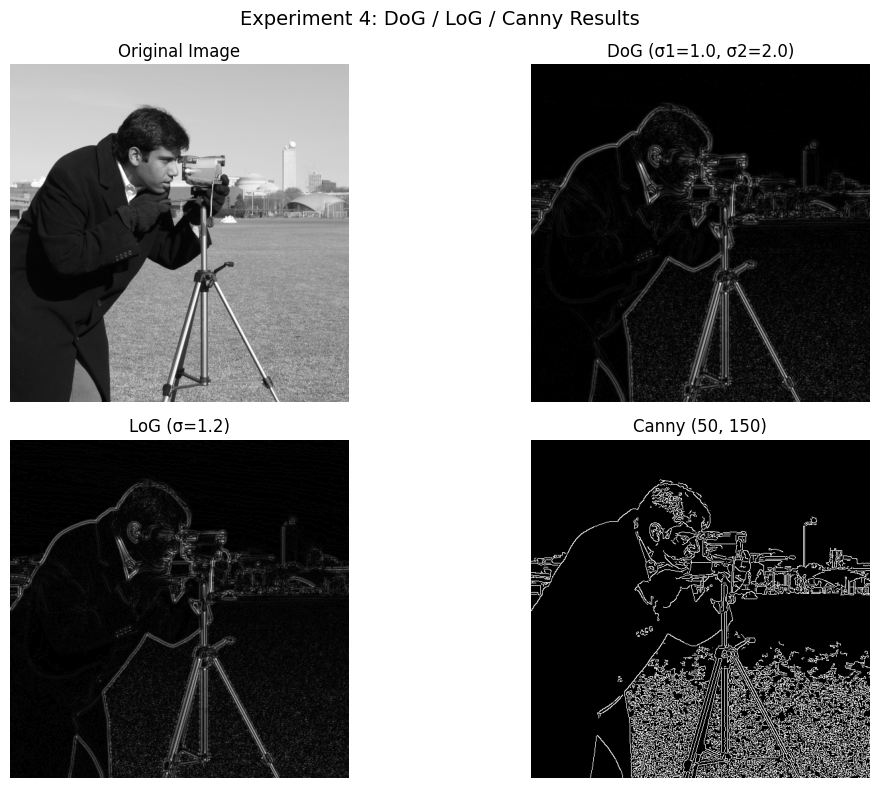

In [ ]:
dog_display = dog_edges(image, 1.0, 2.0)
log_display = log_edges(image, 1.2)
canny = canny_edges(image, 50, 150)

show_grid([image, dog_display, log_display, canny],
          ["Original Image", "DoG (σ1=1.0, σ2=2.0)", "LoG (σ=1.2)", "Canny (50, 150)"],
          2, 2, suptitle="Experiment 4: DoG / LoG / Canny Results")

## Step 5: Edge statistics (used for the observation table)

The percentage of strong edge pixels gives a rough measure of how much each method responds to fine detail and noise.

In [ ]:
def edge_percent(edge_map, thresh=50):
    return 100.0 * np.count_nonzero(edge_map > thresh) / edge_map.size

print(f"DoG   strong-response pixels : {edge_percent(dog_display):.2f} %")
print(f"LoG   strong-response pixels : {edge_percent(log_display):.2f} %")
print(f"Canny edge pixels            : {edge_percent(canny, 0):.2f} %")

DoG   strong-response pixels : 5.51 %
LoG   strong-response pixels : 5.51 %
Canny edge pixels            : 11.82 %


## Student Task 1: DoG with σ1 = 1.0, σ2 = 2.0 vs σ1 = 1.0, σ2 = 3.0

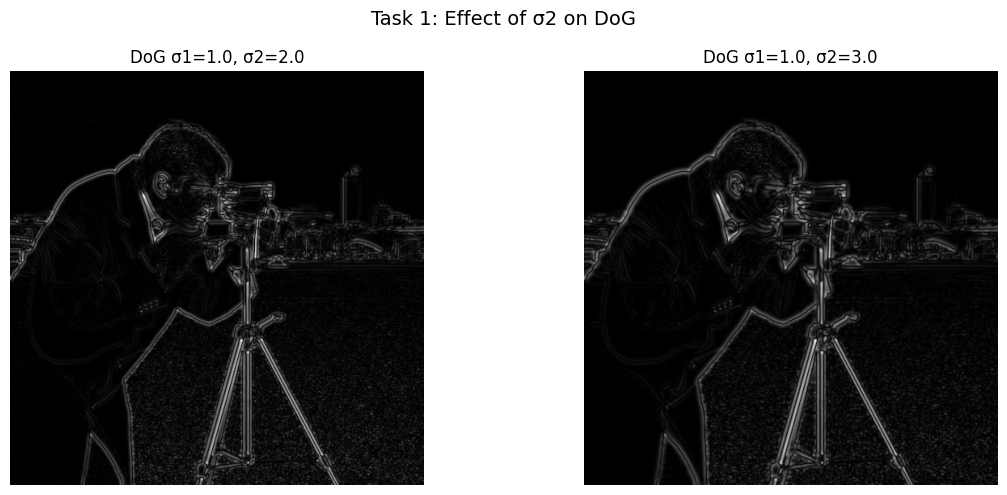

σ2=2.0 strong pixels: 5.51 %
σ2=3.0 strong pixels: 5.68 %


In [ ]:
dog_a = dog_edges(image, 1.0, 2.0)
dog_b = dog_edges(image, 1.0, 3.0)
show_grid([dog_a, dog_b], ["DoG σ1=1.0, σ2=2.0", "DoG σ1=1.0, σ2=3.0"], 1, 2, figsize=(12, 5),
          suptitle="Task 1: Effect of σ2 on DoG")
print(f"σ2=2.0 strong pixels: {edge_percent(dog_a):.2f} %")
print(f"σ2=3.0 strong pixels: {edge_percent(dog_b):.2f} %")

**Observation:** With σ2 = 3.0 the band of frequencies kept by DoG becomes wider, so edges look thicker and brighter, larger structures (the coat, tripod and building outlines) stand out more, and the response spreads further from each edge. With σ2 = 2.0 the edges are thinner and fine texture such as the grass is more visible.

## Student Task 2: LoG with σ = 1.2 vs σ = 2.0

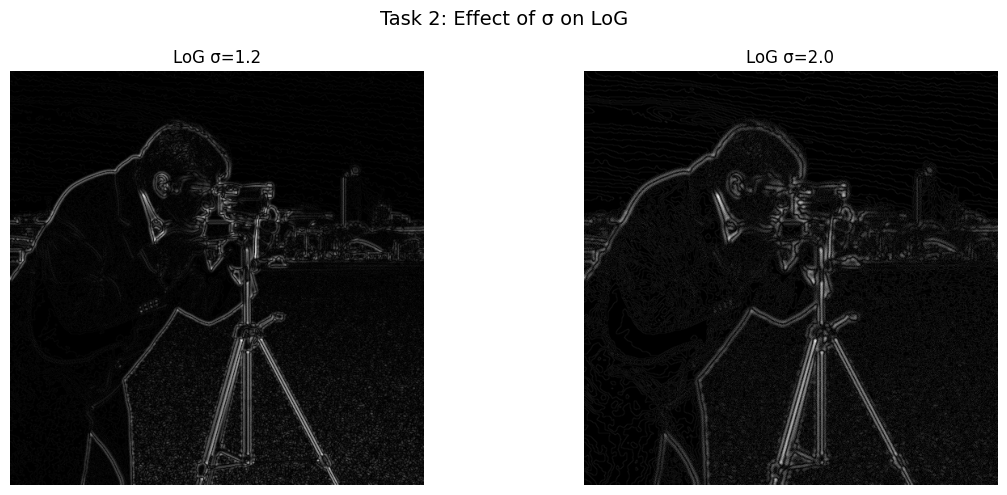

σ=1.2 strong pixels: 5.51 %
σ=2.0 strong pixels: 5.62 %


In [ ]:
log_a = log_edges(image, 1.2)
log_b = log_edges(image, 2.0)
show_grid([log_a, log_b], ["LoG σ=1.2", "LoG σ=2.0"], 1, 2, figsize=(12, 5),
          suptitle="Task 2: Effect of σ on LoG")
print(f"σ=1.2 strong pixels: {edge_percent(log_a):.2f} %")
print(f"σ=2.0 strong pixels: {edge_percent(log_b):.2f} %")

**Observation:** Increasing σ from 1.2 to 2.0 removes fine details: the grass texture, small speckle noise, thin camera parts and facial details fade out. Only the stronger, larger-scale boundaries (the person's outline, tripod legs, horizon/buildings) remain, and they appear smoother and wider.

## Student Task 3: Canny with thresholds (30,100), (50,150) and (100,200)

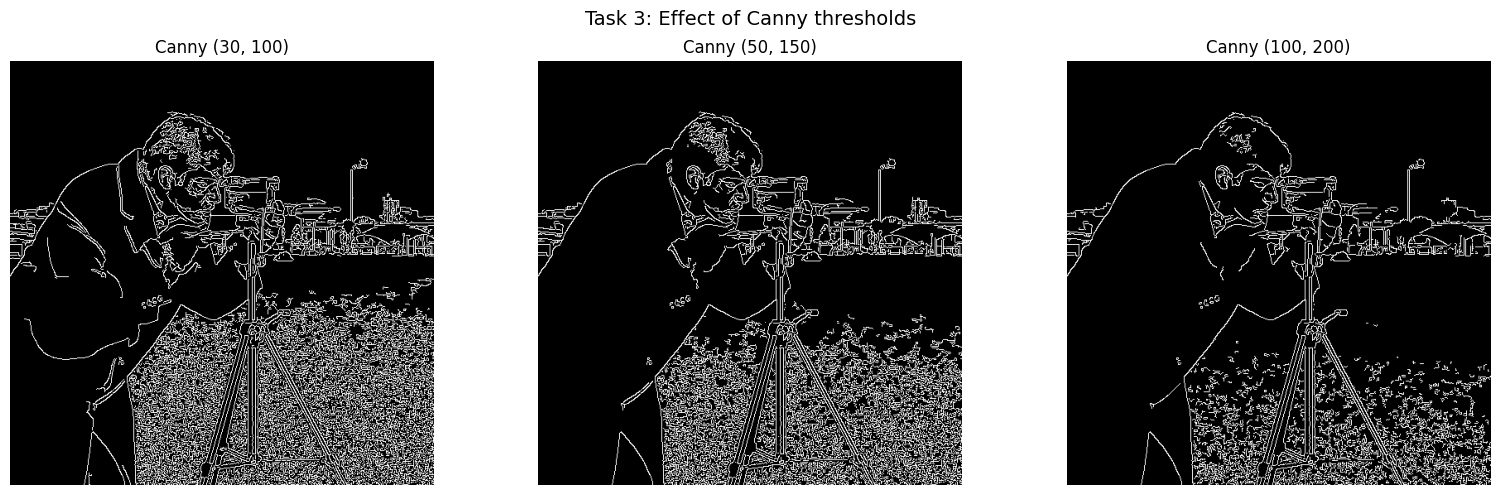

Canny (30, 100): edge pixels = 38878  (14.83 %)
Canny (50, 150): edge pixels = 30980  (11.82 %)
Canny (100, 200): edge pixels = 19686  (7.51 %)


In [ ]:
thresholds = [(30, 100), (50, 150), (100, 200)]
canny_maps = [canny_edges(image, lo, hi) for lo, hi in thresholds]
show_grid(canny_maps, [f"Canny {t}" for t in thresholds], 1, 3, figsize=(16, 5),
          suptitle="Task 3: Effect of Canny thresholds")
for t, c in zip(thresholds, canny_maps):
    print(f"Canny {t}: edge pixels = {np.count_nonzero(c)}  ({edge_percent(c, 0):.2f} %)")

**Observation:** (30,100) keeps the most edges, including many weak texture edges in the grass and some false edges. (50,150) is a balance: main contours are kept with moderate texture. (100,200) keeps only the strongest boundaries; the map is cleanest but some weak real edges break or disappear.

## Parameter comparison (all variations in one figure)

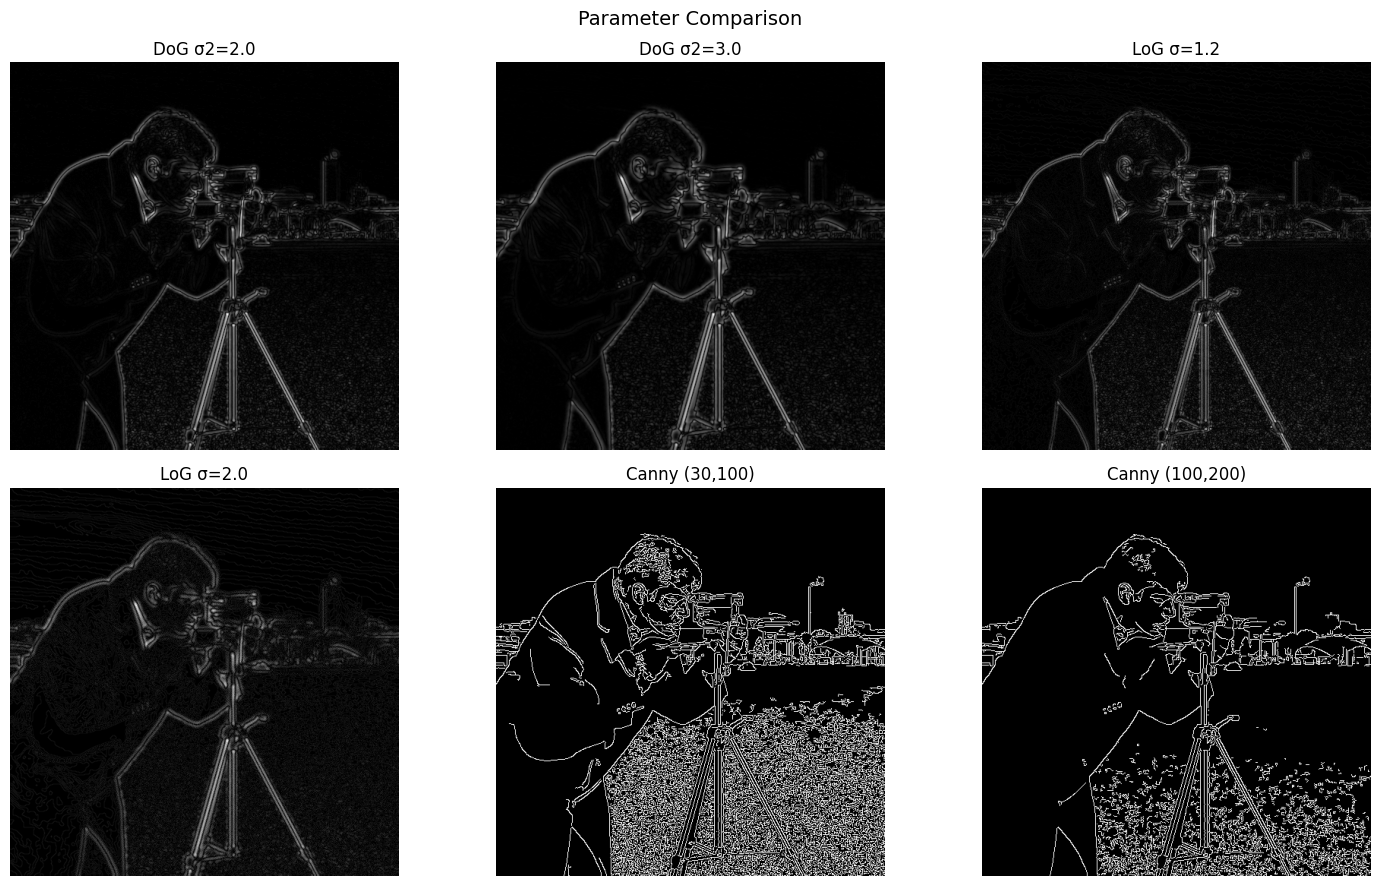

In [ ]:
show_grid([dog_a, dog_b, log_a, log_b, canny_maps[0], canny_maps[2]],
          ["DoG σ2=2.0", "DoG σ2=3.0", "LoG σ=1.2", "LoG σ=2.0", "Canny (30,100)", "Canny (100,200)"],
          2, 3, figsize=(15, 9), suptitle="Parameter Comparison")


## Student Task 4: Three observations comparing DoG, LoG and Canny

1. **Edge thickness:** DoG and LoG give thick, grey-level (non-binary) responses around edges, while Canny gives thin, one-pixel-wide binary edges because of non-maximum suppression.
2. **Noise sensitivity:** LoG (second derivative) is the most sensitive to noise and fine texture; DoG is slightly less sensitive because of the extra smoothing; Canny is the most robust because of smoothing plus double thresholding.
3. **Continuity:** Canny produces the most continuous, connected contours thanks to hysteresis; DoG/LoG outlines are visible but are not linked into clean curves and need extra thresholding to be used directly.

## Student Task 5: Why Gaussian smoothing before derivative-based edge detection?

Derivatives amplify high-frequency changes, and noise is high-frequency. Without smoothing, every noisy pixel would produce a large derivative and be detected as a false edge. Gaussian smoothing first suppresses this noise while keeping the important large intensity changes, and its σ lets us choose the scale of edges to detect. The Gaussian is also separable and has no ringing, so it is efficient and does not create artificial edges.



## Observation Table

| Method | Edge thickness | Noise sensitivity | Continuity | Remarks |
|---|---|---|---|---|
| DoG | Thick, band-like | Moderate | Moderate | Fast approximation of LoG; scale set by σ1, σ2 |
| LoG | Medium–thick, double response | High | Low–moderate | Detects fine detail; zero-crossings mark edges |
| Canny | Thin (1 pixel), binary | Low | High | Best directly usable edge map; depends on thresholds |


## Result

DoG, LoG and Canny edge detection were implemented successfully. Their outputs were compared by varying σ values and Canny thresholds, and their response to intensity changes, fine details and noise was observed. Canny produced the thinnest and most continuous binary edges, while DoG and LoG gave thicker multi-scale responses.